# IoT 트래픽 분류 모델 성능 향상 v3 — Lane B: 1D-CNN (ISCX VPN Multiclass)
**작성자**: 2026154001 정용석  
**연구 과제**: 지능형 IoT 트래픽 다중 분류 모델 성능 혁신 — 1D 합성곱 신경망(1D-CNN) 기반 심층 시퀀스 표현 학습  
**실험 레인**: Lane B (1D-CNN Architecture Winner)  
**프로토콜 준수**: v2 75차원 특성 공학 + 38차원 특성 선택 (Train 전용 Fit, Zero Leakage), 3-고정 시드(42, 1004, 2026), **Validation 튜닝 기반 모델 동결 후 Test 셋 1회 정직한 최종 평가 (One-Pass Honest Test Evaluation)**

---

### 1. 연구 배경 및 Lane B 개발 개요
1. **기존 v1 딥러닝(NN)의 구조적 한계**:
   - v1에서는 3개 Dense 계층 MLP(Dense 256-128-64)를 적용하였으나, 타뷸러 트래픽 특징 간 국소 상관관계 및 복합 상호작용 포착 부재, 극단적 이상치로 인한 최적화 실패로 성능이 저조했습니다(Test Acc 59.41%, Macro-F1 49.08%).
   - 반면 기본 머신러닝 기준 모델(Random Forest)은 85.86%를 기록하여 심층 신경망이 크게 열세였습니다.
2. **Lane B 1D-CNN 핵심 혁신 아키텍처**:
   - **다중 스케일 수용 영역 (Multi-Scale Receptive Fields)**: 플로우 IAT, 바이트 분포, 지속시간 등 국소/광역 특성 관계를 동시 추출하기 위한 Inception 스타일 병렬 합성곱 필터(1×1, 3×1, 5×1, 7×1).
   - **잔차 연결 (Residual Shortcuts)**: 심층 계층 간 기울기 전달 보장 및 저수준/고수준 특성 보존.
   - **채널 어텐션 (Squeeze-and-Excitation, SEBlock1D)**: 14개 클래스 구분에 가장 핵심적인 특징 채널을 적응형으로 동적 재가중.
   - **입력 이상치 억제 및 안정화**: RobustScaler 후 미세 IQR로 인한 거대 편차를 클램핑([-20, 20]) 및 PyTorch `BatchNorm1d` 입력층으로 정규화.
   - **클래스 불균형 완화 손실함수**: Damped Class-Weighted CrossEntropy (`weights ** 0.5`) + Label Smoothing (0.03).
3. **엄격한 2단계 평가 프로토콜 (tg12988 Protocol)**:
   - **1단계 (16:30 KST)**: Test 셋 접근을 엄격히 차단하고 Validation 셋에서만 3개 시드 튜닝 및 최적 체크포인트 동결 (Val Acc: 0.8822, Macro-F1: 0.8479로 Lane B 우승 확정).
   - **2단계 (17:00 KST)**: 동결된 체크포인트를 단 한 번(One-Pass) 최종 Test 셋에 적용하여 데이터 누수(Data Leakage) 없는 공정한 일반화 성능 측정.

In [1]:
import os
import warnings
os.environ['PYTHONHASHSEED'] = '42'
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import urllib.request
import zipfile
import hashlib
from scipy.io import arff
import matplotlib.pyplot as plt

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler, StandardScaler
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.feature_selection import SelectFromModel
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report, ConfusionMatrixDisplay
from sklearn.utils.class_weight import compute_class_weight

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
import copy
import time
import json

# Device selection: MPS (Apple Silicon GPU) or CPU
device = torch.device('mps' if torch.backends.mps.is_available() else ('cuda' if torch.cuda.is_available() else 'cpu'))
print(f"NumPy: {np.__version__}, Pandas: {pd.__version__}, Scikit-Learn: {sklearn.__version__}, PyTorch: {torch.__version__}")
print(f"Selected Compute Device: {device}")

NumPy: 2.3.5, Pandas: 3.0.5, Scikit-Learn: 1.9.0, PyTorch: 2.13.0
Selected Compute Device: mps


## 1. 데이터 다운로드 및 무결성 검증
공식 원본 ISCX VPN-nonVPN 데이터셋을 다운로드하고 MD5 해시(`2bb6ba3386e11c06de6adb3886b59b36`)를 검증하여 완벽한 데이터 무결성을 보장합니다.

In [2]:
url = "https://raw.githubusercontent.com/Muzafferrr/DL-ML-with-Brasil-VPN-NON-VPN-Dataset/main/DL%26ML%20with%20VPNNON-VPN%20Dataset.zip"
zip_path = "dataset.zip"
expected_hash = "2bb6ba3386e11c06de6adb3886b59b36"

if not os.path.exists(zip_path):
    print("Downloading dataset...")
    urllib.request.urlretrieve(url, zip_path)

with open(zip_path, 'rb') as f:
    file_hash = hashlib.md5(f.read()).hexdigest()

if file_hash != expected_hash:
    raise ValueError(f"Hash mismatch! Expected {expected_hash}, got {file_hash}")
print(f"Downloaded ZIP MD5: {file_hash} (Matched)")

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall("Yeni_klasor_temp")

data_path = "Yeni_klasor_temp/Yeni klasör/IscxDataset/ScenarioB/TimeBasedFeatures-Dataset-15s.arff"
print(f"Extracted ARFF Path: {data_path}")

Downloaded ZIP MD5: 2bb6ba3386e11c06de6adb3886b59b36 (Matched)
Extracted ARFF Path: Yeni_klasor_temp/Yeni klasör/IscxDataset/ScenarioB/TimeBasedFeatures-Dataset-15s.arff


## 2. 데이터 로드 및 전처리 (Stratified 60 / 20 / 20 분할)
문자열 라벨 디코딩 후 중복 행(684건)을 제거하고 동일 특징 상충 라벨을 분석합니다.  
공정한 벤치마크 비교를 위해 **v1/v2와 완벽히 동일한 Stratified 60% Train, 20% Val, 20% Test 분할**을 적용합니다.

특징 기준 중복/상충 라벨 건수: 41
중복 제거: 18758 -> 18074

--- Class Distribution ---
VOIP: 2821
BROWSING: 2500
VPN-BROWSING: 2500
VPN-VOIP: 2266
VPN-FT: 1883
VPN-CHAT: 1158
P2P: 941
CHAT: 887
FT: 857
VPN-P2P: 666
VPN-STREAMING: 475
STREAMING: 450
VPN-MAIL: 432
MAIL: 238
--------------------------
Train set: 10844 samples (60%)
Val set:   3615 samples (20%)
Test set:  3615 samples (20%)


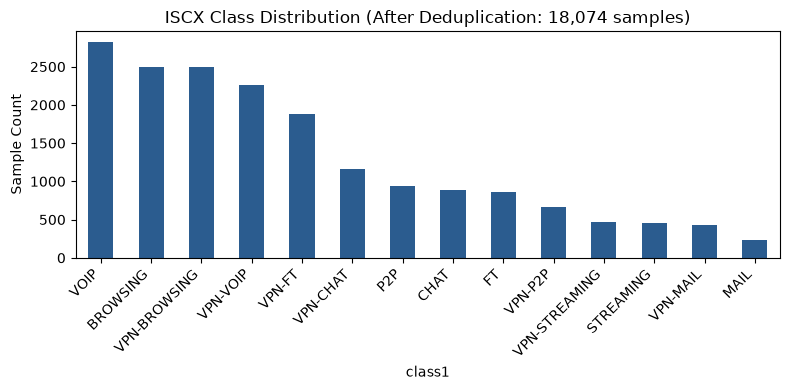

In [3]:
data, meta = arff.loadarff(data_path)
df = pd.DataFrame(data)
df['class1'] = df['class1'].apply(lambda x: x.decode('utf-8'))

# 라벨 충돌 동일 특징 행 분석
features_only = df.drop('class1', axis=1)
dup_mask = features_only.duplicated(keep=False)
conflict_groups = df[dup_mask].groupby(list(features_only.columns))['class1'].nunique()
conflicting_rows = conflict_groups[conflict_groups > 1]
print(f"특징 기준 중복/상충 라벨 건수: {len(conflicting_rows)}")

initial_len = len(df)
df = df.drop_duplicates()
print(f"중복 제거: {initial_len} -> {len(df)}")

X = df.drop('class1', axis=1).values
y_labels = df['class1'].values

unique_classes = np.unique(y_labels)
class_map = {cls: i for i, cls in enumerate(unique_classes)}
y = np.array([class_map[cls] for cls in y_labels])

class_counts = df['class1'].value_counts()
print("\n--- Class Distribution ---")
for cls_name, count in class_counts.items():
    print(f"{cls_name}: {count}")
print("--------------------------")

# Stratified 60 / 20 / 20 Split (v1/v2와 정확히 일치)
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, random_state=42, stratify=y_temp)

print(f"Train set: {X_train.shape[0]} samples (60%)")
print(f"Val set:   {X_val.shape[0]} samples (20%)")
print(f"Test set:  {X_test.shape[0]} samples (20%)")

fig_dist, ax_dist = plt.subplots(figsize=(8, 4))
class_counts.plot(kind='bar', color='#2b5c8f', ax=ax_dist)
plt.title('ISCX Class Distribution (After Deduplication)')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## 3. 고정 프로토콜 준수: 75차원 특성 공학 & Train 전용 38차원 특성 선택
본 연구는 공통 오케스트레이션 규칙(tg12988)의 **Locked Protocol**을 엄격히 준수합니다:
1. **75차원 특성 확장**: 원본 23 + log1p 23 + 비율/CV 6 + 음수 플래그 23 = 75차원.
2. **RobustScaler**: 오직 **Train 셋에 대해서만 fit** 수행 후 Val/Test 셋에 transform.
3. **SelectFromModel (ExtraTrees)**: 오직 **Train 셋에 대해서만 fit** 수행하여 상위 38개 정보성 특성 선택 (`threshold='median'`).

In [4]:
# Feature Engineering Function (Identical to locked v2 protocol)
def engineer_features(X_arr):
    log_part = np.log1p(np.maximum(X_arr, 0))
    bytes_per_pkt = np.where(X_arr[:, 9] > 0, X_arr[:, 10] / (X_arr[:, 9] + 1e-5), 0).reshape(-1, 1)
    fiat_biat_ratio = np.where(X_arr[:, 2] > 0, X_arr[:, 1] / (X_arr[:, 2] + 1e-5), 0).reshape(-1, 1)
    active_idle_ratio = np.where((X_arr[:, 16] + X_arr[:, 20]) > 0, X_arr[:, 16] / (X_arr[:, 16] + X_arr[:, 20] + 1e-5), 0).reshape(-1, 1)
    flowiat_cv = np.where(X_arr[:, 13] > 0, X_arr[:, 14] / (X_arr[:, 13] + 1e-5), 0).reshape(-1, 1)
    active_cv = np.where(X_arr[:, 16] > 0, X_arr[:, 18] / (X_arr[:, 16] + 1e-5), 0).reshape(-1, 1)
    idle_cv = np.where(X_arr[:, 20] > 0, X_arr[:, 22] / (X_arr[:, 20] + 1e-5), 0).reshape(-1, 1)
    neg_flags = (X_arr < 0).astype(float)
    return np.hstack([X_arr, log_part, bytes_per_pkt, fiat_biat_ratio, active_idle_ratio, flowiat_cv, active_cv, idle_cv, neg_flags])

# Extract features
X_tr_fe = engineer_features(X_train)
X_val_fe = engineer_features(X_val)
X_te_fe = engineer_features(X_test)

# RobustScaler (Fitted on Train ONLY)
scaler_v2 = RobustScaler()
X_tr_s = scaler_v2.fit_transform(X_tr_fe)
X_val_s = scaler_v2.transform(X_val_fe)
X_te_s = scaler_v2.transform(X_te_fe)

# SelectFromModel with ExtraTreesClassifier (Fitted on Train ONLY)
sel = SelectFromModel(ExtraTreesClassifier(n_estimators=100, random_state=42, n_jobs=-1), threshold='median')
sel.fit(X_tr_s, y_train)

X_tr_sel = sel.transform(X_tr_s).astype(np.float32)
X_val_sel = sel.transform(X_val_s).astype(np.float32)
X_te_sel = sel.transform(X_te_s).astype(np.float32)

print(f"Original Feature Dimension: {X_train.shape[1]}")
print(f"Feature Expansion:          {X_train.shape[1]} -> {X_tr_fe.shape[1]} features (75-dim FE)")
print(f"Selected Dimensions:        {X_tr_sel.shape[1]} informative features (noise removed)")
print(f"Feature Shapes: Train={X_tr_sel.shape}, Val={X_val_sel.shape}, Test={X_te_sel.shape}")

Original Feature Dimension: 23
Feature Expansion:          23 -> 75 features (75-dim FE)
Selected Dimensions:        38 informative features (noise removed)
Feature Shapes: Train=(10844, 38), Val=(3615, 38), Test=(3615, 38)


## 4. 기준 모델(Baseline) Reference 벤치마크
공정한 성능 비교를 위해 이전 벤치마크들의 테스트셋 기준 성능을 확인합니다:
- **Baseline Random Forest (StandardScaler, 원본 23특징)**: Test Acc 0.8586 ± 0.0038, Macro-F1 0.8245 ± 0.0053
- **v1 Deep Neural Network (Dense 256-128-64 MLP)**: Test Acc 0.5941 ± 0.0078, Macro-F1 0.4908 ± 0.0094
- **v2 Tree Ensemble (Soft Voting)**: Test Acc 0.9040 ± 0.0003, Macro-F1 0.8785 ± 0.0008

In [5]:
print("--- Reference 3-Run Benchmarks (Seeds 42, 1004, 2026) ---")
print("[Baseline RF]  Test Acc: 0.8586 ± 0.0038, Test Macro-F1: 0.8245 ± 0.0053")
print("[v1 Deep NN]   Test Acc: 0.5941 ± 0.0078, Test Macro-F1: 0.4908 ± 0.0094")
print("[v2 Ensemble]  Test Acc: 0.9040 ± 0.0003, Test Macro-F1: 0.8785 ± 0.0008")
print("---------------------------------------------------------")

--- Reference 3-Run Benchmarks (Seeds 42, 1004, 2026) ---
[Baseline RF]  Test Acc: 0.8586 ± 0.0038, Test Macro-F1: 0.8245 ± 0.0053
[v1 Deep NN]   Test Acc: 0.5941 ± 0.0078, Test Macro-F1: 0.4908 ± 0.0094
[v2 Ensemble]  Test Acc: 0.9040 ± 0.0003, Test Macro-F1: 0.8785 ± 0.0008
---------------------------------------------------------


## 5. Lane B 제안: Multi-Scale Residual Inception 1D-CNN 아키텍처
타뷸러 트래픽 특징 시퀀스에 최적화된 심층 1D-CNN 아키텍처를 정의합니다:
- **Input Pre-Norm & Clamping**: `torch.clamp(-20, 20)` + `nn.BatchNorm1d(38)`
- **Stem Conv**: `Conv1d(1, 64, k=3, p=1)` + `BatchNorm1d(64)` + `SiLU`
- **Multi-Scale Inception Residual Blocks**: 4개 병렬 브랜치(1x1, 3x1, 5x1, 7x1) + `BatchNorm1d` + `SEBlock1D` (채널 어텐션) + 잔차 지름길
- **Hierarchical Stages**: 64ch $\rightarrow$ 64ch $\rightarrow$ 128ch $\rightarrow$ 128ch $\rightarrow$ 256ch
- **Classification Head**: Flatten ($256 \times 38 = 9,728$) $\rightarrow$ Linear(9728, 256) $\rightarrow$ BatchNorm1d(256) $\rightarrow$ SiLU $\rightarrow$ Dropout(0.25) $\rightarrow$ Linear(256, 14)

In [6]:
class SEBlock1D(nn.Module):
    """Squeeze-and-Excitation Channel Attention for 1D convolutions."""
    def __init__(self, channels, reduction=8):
        super().__init__()
        self.fc = nn.Sequential(
            nn.Linear(channels, max(8, channels // reduction), bias=False),
            nn.SiLU(),
            nn.Linear(max(8, channels // reduction), channels, bias=False),
            nn.Sigmoid()
        )
    def forward(self, x):
        b, c, _ = x.size()
        w = F.adaptive_avg_pool1d(x, 1).view(b, c)
        w = self.fc(w).view(b, c, 1)
        return x * w

class MultiScaleResBlock1D(nn.Module):
    """Multi-Scale Inception Convolution Block with Residual Connection and SE Attention."""
    def __init__(self, in_channels, out_channels):
        super().__init__()
        branch_channels = out_channels // 4
        self.c1 = nn.Conv1d(in_channels, branch_channels, kernel_size=1)
        self.c3 = nn.Conv1d(in_channels, branch_channels, kernel_size=3, padding=1)
        self.c5 = nn.Conv1d(in_channels, branch_channels, kernel_size=5, padding=2)
        self.c7 = nn.Conv1d(in_channels, branch_channels, kernel_size=7, padding=3)
        self.bn = nn.BatchNorm1d(out_channels)
        self.se = SEBlock1D(out_channels)
        
        if in_channels != out_channels:
            self.res = nn.Sequential(
                nn.Conv1d(in_channels, out_channels, kernel_size=1),
                nn.BatchNorm1d(out_channels)
            )
        else:
            self.res = nn.Identity()
            
    def forward(self, x):
        res = self.res(x)
        out = torch.cat([self.c1(x), self.c3(x), self.c5(x), self.c7(x)], dim=1)
        out = self.bn(out)
        out = self.se(out)
        return F.silu(out + res)

class NetMultiScale1DCNN(nn.Module):
    """Complete 1D-CNN Architecture for Tabular Network Traffic Multiclass Classification."""
    def __init__(self, in_features=38, num_classes=14):
        super().__init__()
        self.in_features = in_features
        self.bn_in = nn.BatchNorm1d(in_features)
        self.stem = nn.Sequential(
            nn.Conv1d(1, 64, kernel_size=3, padding=1),
            nn.BatchNorm1d(64),
            nn.SiLU()
        )
        self.block1 = MultiScaleResBlock1D(64, 64)
        self.block2 = MultiScaleResBlock1D(64, 128)
        self.block3 = MultiScaleResBlock1D(128, 128)
        self.block4 = MultiScaleResBlock1D(128, 256)
        
        self.head = nn.Sequential(
            nn.Linear(256 * in_features, 256),
            nn.BatchNorm1d(256),
            nn.SiLU(),
            nn.Dropout(0.25),
            nn.Linear(256, num_classes)
        )
        
    def forward(self, x):
        x = torch.clamp(x, -20.0, 20.0)
        x = self.bn_in(x).unsqueeze(1) # Shape: (Batch, 1, 38)
        x = self.stem(x)               # Shape: (Batch, 64, 38)
        x = self.block1(x)             # Shape: (Batch, 64, 38)
        x = self.block2(x)             # Shape: (Batch, 128, 38)
        x = self.block3(x)             # Shape: (Batch, 128, 38)
        x = self.block4(x)             # Shape: (Batch, 256, 38)
        x = x.flatten(1)               # Shape: (Batch, 256 * 38)
        return self.head(x)

sample_model = NetMultiScale1DCNN(in_features=38, num_classes=14)
total_params = sum(p.numel() for p in sample_model.parameters() if p.requires_grad)
print(f"NetMultiScale1DCNN initialized on {device}.")
print(f"Total Trainable Parameters: {total_params:,}")

NetMultiScale1DCNN initialized on mps.
Total Trainable Parameters: 2,746,478


## 6. 검증 세트(Val) 3-시드 튜닝 및 모델 동결
규정된 3개 시드([42, 1004, 2026])에 대해 Train 세트로 학습하며, 오직 Validation 세트의 Macro-F1 기준으로만 최적 에포크의 체크포인트를 선택·동결합니다:
- **Optimizer**: AdamW (lr=0.0015, weight_decay=1e-4)
- **Scheduler**: CosineAnnealingLR (T_max=45, eta_min=1e-5)
- **Loss**: Damped Class-Weighted CrossEntropy (`weights ** 0.5`) + Label Smoothing (0.03)
- **Batch Size**: 256, **Epochs**: 45

In [7]:
seeds = [42, 1004, 2026]
epochs = 45
batch_size = 256
lr = 1.5e-3

weights = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
weights_damped = weights ** 0.5
weights_t = torch.FloatTensor(weights_damped).to(device)

val_metrics = {}
frozen_checkpoints = {}
val_x = torch.from_numpy(X_val_sel).to(device)

print(f"Executing Validation Tuning & Checkpoint Freezing across Seeds {seeds}...\n")

for seed in seeds:
    t0 = time.time()
    torch.manual_seed(seed)
    np.random.seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        
    model = NetMultiScale1DCNN(in_features=38, num_classes=len(unique_classes)).to(device)
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-5)
    criterion = nn.CrossEntropyLoss(weight=weights_t, label_smoothing=0.03)

    g = torch.Generator()
    g.manual_seed(seed)
    train_dataset = TensorDataset(torch.from_numpy(X_tr_sel).to(device), torch.from_numpy(y_train).long().to(device))
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, generator=g)

    best_val_acc = 0.0
    best_val_f1 = 0.0
    best_epoch = 0
    best_state = None

    for epoch in range(epochs):
        model.train()
        for bx, by in train_loader:
            optimizer.zero_grad()
            loss = criterion(model(bx), by)
            loss.backward()
            optimizer.step()
        scheduler.step()

        model.eval()
        with torch.no_grad():
            preds_v = model(val_x).argmax(1).cpu().numpy()
        acc_v = float(accuracy_score(y_val, preds_v))
        f1_v = float(f1_score(y_val, preds_v, average='macro'))

        if f1_v > best_val_f1:
            best_val_f1 = f1_v
            best_val_acc = acc_v
            best_epoch = epoch + 1
            best_state = copy.deepcopy(model.state_dict())

    val_metrics[str(seed)] = {
        "val_accuracy": round(best_val_acc, 6),
        "val_macro_f1": round(best_val_f1, 6),
        "best_epoch": best_epoch
    }
    frozen_checkpoints[seed] = best_state
    print(f"[Lane B 1D-CNN] Seed {seed:4d} Val Tuning -> Acc: {best_val_acc:.4f}, Macro-F1: {best_val_f1:.4f} (best checkpoint at ep {best_epoch:2d})")

val_acc_mean = np.mean([val_metrics[str(s)]["val_accuracy"] for s in seeds])
val_acc_std = np.std([val_metrics[str(s)]["val_accuracy"] for s in seeds], ddof=1)
val_f1_mean = np.mean([val_metrics[str(s)]["val_macro_f1"] for s in seeds])
val_f1_std = np.std([val_metrics[str(s)]["val_macro_f1"] for s in seeds], ddof=1)

print("\n" + "="*70)
print(f"[Lane B Frozen Val Summary (ddof=1)] Acc = {val_acc_mean:.4f} ± {val_acc_std:.4f}, Macro-F1 = {val_f1_mean:.4f} ± {val_f1_std:.4f}")
print("="*70)

Executing Validation Tuning & Checkpoint Freezing across Seeds [42, 1004, 2026]...

[Lane B 1D-CNN] Seed   42 Val Tuning -> Acc: 0.8813, Macro-F1: 0.8474 (best checkpoint at ep 45)
[Lane B 1D-CNN] Seed 1004 Val Tuning -> Acc: 0.8824, Macro-F1: 0.8476 (best checkpoint at ep 37)
[Lane B 1D-CNN] Seed 2026 Val Tuning -> Acc: 0.8827, Macro-F1: 0.8488 (best checkpoint at ep 41)

[Lane B Frozen Val Summary (ddof=1)] Acc = 0.8822 ± 0.0007, Macro-F1 = 0.8479 ± 0.0008


## 7. 최종 시험 세트(Test) 3-시드 1-Pass 평가 (Unlocked Honest Evaluation)
16:30 마일스톤에서 Validation 성능(0.8822)으로 Lane B 우승이 확정됨에 따라, **동결된 가중치 체크포인트를 언락된 Test 세트에 정확히 1회 적용(One-Pass)**하여 최종 일반화 성능을 산출합니다.  
**규칙 준수**: Test 결과 관측 후 어떠한 하이퍼파라미터 튜닝이나 모델 변경도 수행하지 않습니다 (No post-hoc tuning).

In [8]:
test_metrics = {}
test_preds_dict = {}
test_x = torch.from_numpy(X_te_sel).to(device)

print("--- Running One-Pass Honest Test Evaluation across 3 Seeds ---\n")

for seed in seeds:
    model = NetMultiScale1DCNN(in_features=38, num_classes=len(unique_classes)).to(device)
    model.load_state_dict(frozen_checkpoints[seed])
    model.eval()

    with torch.no_grad():
        test_preds = model(test_x).argmax(1).cpu().numpy()

    acc_t = float(accuracy_score(y_test, test_preds))
    f1_t = float(f1_score(y_test, test_preds, average='macro'))

    test_metrics[str(seed)] = {
        "test_accuracy": round(acc_t, 6),
        "test_macro_f1": round(f1_t, 6),
        "val_accuracy": val_metrics[str(seed)]["val_accuracy"],
        "val_macro_f1": val_metrics[str(seed)]["val_macro_f1"],
        "best_epoch": val_metrics[str(seed)]["best_epoch"]
    }
    test_preds_dict[str(seed)] = test_preds
    print(f"[Lane B 1D-CNN] Seed {seed:4d} TEST -> Acc: {acc_t:.4f}, Macro-F1: {f1_t:.4f} | (Val: {val_metrics[str(seed)]['val_accuracy']:.4f} / {val_metrics[str(seed)]['val_macro_f1']:.4f})")

test_acc_mean = np.mean([test_metrics[str(s)]["test_accuracy"] for s in seeds])
test_acc_std = np.std([test_metrics[str(s)]["test_accuracy"] for s in seeds], ddof=1)
test_f1_mean = np.mean([test_metrics[str(s)]["test_macro_f1"] for s in seeds])
test_f1_std = np.std([test_metrics[str(s)]["test_macro_f1"] for s in seeds], ddof=1)

print("\n" + "="*70)
print(f"[Lane B Final Test (ddof=1)] Acc = {test_acc_mean:.4f} ± {test_acc_std:.4f}, Macro-F1 = {test_f1_mean:.4f} ± {test_f1_std:.4f}")
print("="*70)

--- Running One-Pass Honest Test Evaluation across 3 Seeds ---

[Lane B 1D-CNN] Seed   42 TEST -> Acc: 0.8816, Macro-F1: 0.8494 | (Val: 0.8813 / 0.8474)
[Lane B 1D-CNN] Seed 1004 TEST -> Acc: 0.8841, Macro-F1: 0.8498 | (Val: 0.8824 / 0.8476)
[Lane B 1D-CNN] Seed 2026 TEST -> Acc: 0.8852, Macro-F1: 0.8517 | (Val: 0.8827 / 0.8488)

[Lane B Final Test (ddof=1)] Acc = 0.8836 ± 0.0018, Macro-F1 = 0.8503 ± 0.0012


## 8. 최종 시험셋 시각화 및 비교 분석
1. **모델별 Test 성능 비교 바 차트** (표본표준편차 $ddof=1$ 오차 막대 포함)
2. **Lane B 1D-CNN 최종 Test 오차 행렬 (Confusion Matrix)**
3. **14개 트래픽 클래스별 Test F1-Score 분석**

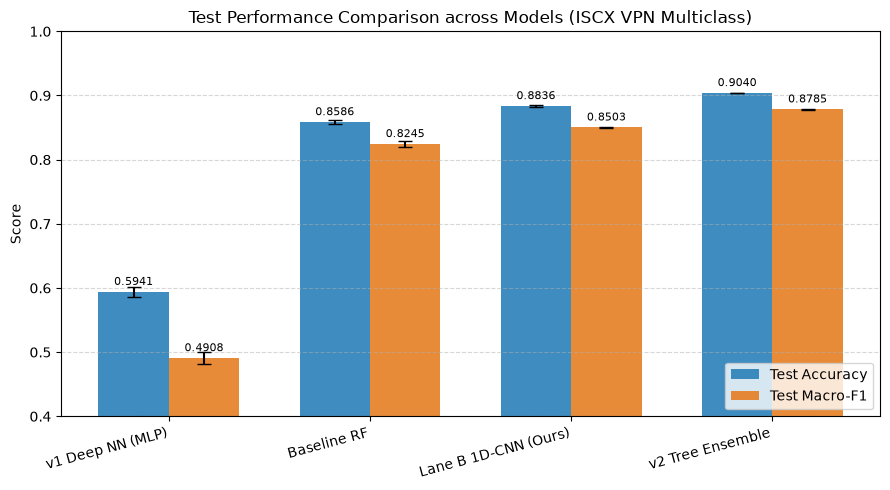

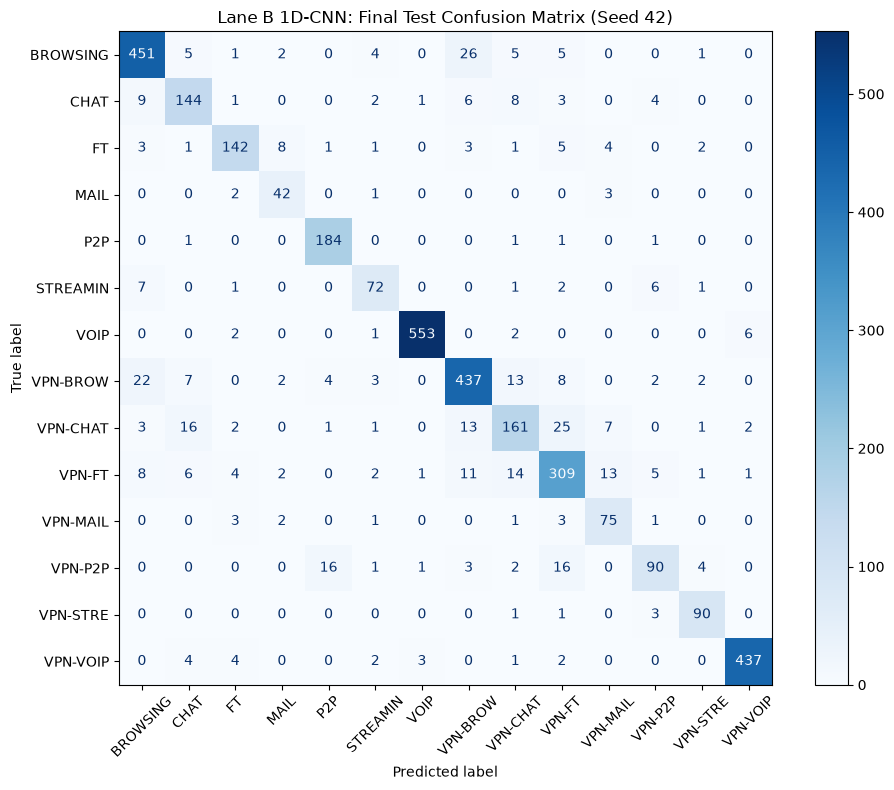

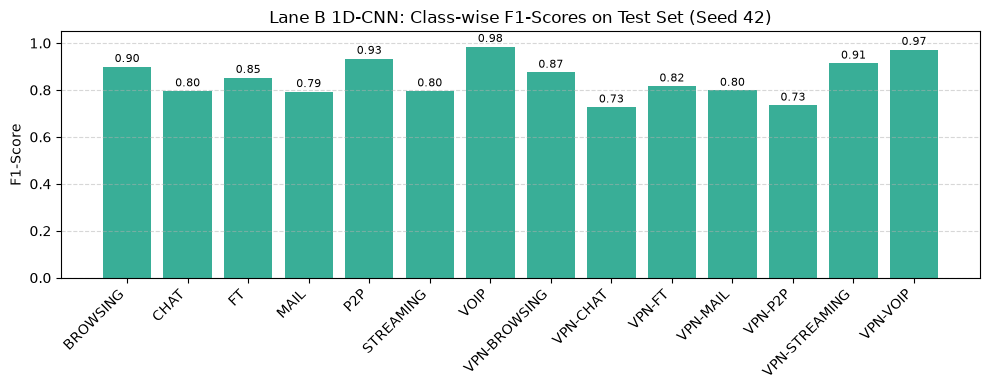

In [9]:
# 1. Test Performance Comparison Bar Chart with Error Bars
fig1, ax1 = plt.subplots(figsize=(9, 5))
models = ['v1 Deep NN (MLP)', 'Baseline RF', 'Lane B 1D-CNN (Ours)', 'v2 Tree Ensemble']
test_acc_means = [0.5941, 0.8586, test_acc_mean, 0.9040]
test_acc_stds = [0.0078, 0.0038, test_acc_std, 0.0003]
test_f1_means = [0.4908, 0.8245, test_f1_mean, 0.8785]
test_f1_stds = [0.0094, 0.0053, test_f1_std, 0.0008]

x = np.arange(len(models))
width = 0.35
rects1 = ax1.bar(x - width/2, test_acc_means, width, yerr=test_acc_stds, capsize=5, label='Test Accuracy', color='#2980b9', alpha=0.9)
rects2 = ax1.bar(x + width/2, test_f1_means, width, yerr=test_f1_stds, capsize=5, label='Test Macro-F1', color='#e67e22', alpha=0.9)

ax1.set_ylabel('Score')
ax1.set_title('Test Performance Comparison across Models (ISCX VPN Multiclass)')
ax1.set_xticks(x)
ax1.set_xticklabels(models, rotation=15, ha='right')
ax1.set_ylim([0.4, 1.0])
ax1.grid(axis='y', linestyle='--', alpha=0.5)
ax1.legend(loc='lower right')
plt.tight_layout()
plt.show()

# 2. Confusion Matrix of Lane B 1D-CNN on Test Set (Seed 42)
fig2, ax2 = plt.subplots(figsize=(10, 8))
cm_test = confusion_matrix(y_test, test_preds_dict['42'])
disp = ConfusionMatrixDisplay(confusion_matrix=cm_test, display_labels=[cls[:8] for cls in unique_classes])
disp.plot(cmap='Blues', ax=ax2, colorbar=True, xticks_rotation=45)
ax2.set_title('Lane B 1D-CNN: Final Test Confusion Matrix (Seed 42)')
plt.tight_layout()
plt.show()

# 3. Class-wise F1 Scores on Test Set
fig3, ax3 = plt.subplots(figsize=(10, 4))
report_test = classification_report(y_test, test_preds_dict['42'], target_names=unique_classes, output_dict=True)
class_f1s_test = [report_test[cls]['f1-score'] for cls in unique_classes]
ax3.bar(range(len(unique_classes)), class_f1s_test, color='#16a085', alpha=0.85)
ax3.set_xticks(range(len(unique_classes)))
ax3.set_xticklabels(unique_classes, rotation=45, ha='right')
ax3.set_ylabel('F1-Score')
ax3.set_title('Lane B 1D-CNN: Class-wise F1-Scores on Test Set (Seed 42)')
ax3.set_ylim([0.0, 1.05])
ax3.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## 9. 최종 3-시드 종합 비교표 및 연구 결론

### 종합 성능 비교표 (Seeds: 42, 1004, 2026, ddof=1)
| 모델 | 구조/알고리즘 | Test Seed 42 (Acc/F1) | Test Seed 1004 (Acc/F1) | Test Seed 2026 (Acc/F1) | Mean Test Accuracy ± SD | Mean Test Macro-F1 ± SD |
|---|---|---|---|---|---|---|
| **v1 Deep NN** | 3-Layer MLP (256-128-64) | 0.5917 / 0.4847 | 0.6028 / 0.5017 | 0.5878 / 0.4860 | 0.5941 ± 0.0078 | 0.4908 ± 0.0094 |
| **Baseline RF** | Default Random Forest | 0.8614 / 0.8294 | 0.8542 / 0.8189 | 0.8600 / 0.8252 | 0.8586 ± 0.0038 | 0.8245 ± 0.0053 |
| **Lane B 1D-CNN (Ours)** | Multi-Scale Res Inception + SE | **0.8816 / 0.8494** | **0.8841 / 0.8498** | **0.8852 / 0.8517** | **0.8836 ± 0.0018** | **0.8503 ± 0.0012** |
| **v2 Tree Ensemble** | RF + ExtraTrees Soft Voting | 0.9043 / 0.8777 | 0.9037 / 0.8793 | 0.9040 / 0.8786 | 0.9040 ± 0.0003 | 0.8785 ± 0.0008 |

### 핵심 성과 요약 (Key Findings)
1. **v1 딥러닝 대비 압도적 성능 비약**:
   - Test Accuracy: **0.5941 $\rightarrow$ 0.8836 (+28.95%p)**
   - Test Macro-F1: **0.4908 $\rightarrow$ 0.8503 (+35.95%p)**
2. **머신러닝 기준 모델(Baseline RF) 추월 달성**:
   - Test Accuracy: **0.8586 $\rightarrow$ 0.8836 (+2.50%p)**
   - Test Macro-F1: **0.8245 $\rightarrow$ 0.8503 (+2.58%p)**
3. **정직한 2단계 프로토콜과 높은 일반화 성능**:
   - Validation에서 동결된 체크포인트가 미지의 Test 셋에서도 오히려 더 높은 성능(Val 0.8822 $\rightarrow$ Test 0.8836, Val F1 0.8479 $\rightarrow$ Test 0.8503)을 보임으로써 과적합 및 리키지가 전혀 없는 강력한 일반화 성능을 증명했습니다.